# Calculate an asymmetry score of a skin lesion 

In [1]:
import sys
import os

# Add the project root to the system path to import local modules
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

In [2]:
from python.dualbranch.ham10000_dataset_manager import HAM10000DatasetManager
from python.utils.image_asymmetry import ImageAsymmetry
import matplotlib.pyplot as plt

In [3]:
# load the dataset manager
dataset_manager = HAM10000DatasetManager(data_dir="/home/vertyx/Documents/dermascan/data")

# load the dataset
# dataset = dataset_manager.load_dataset(data_dir="/home/vertyx/Documents/dermascan/data")
dataset_manager.load_cleaned_metadata()

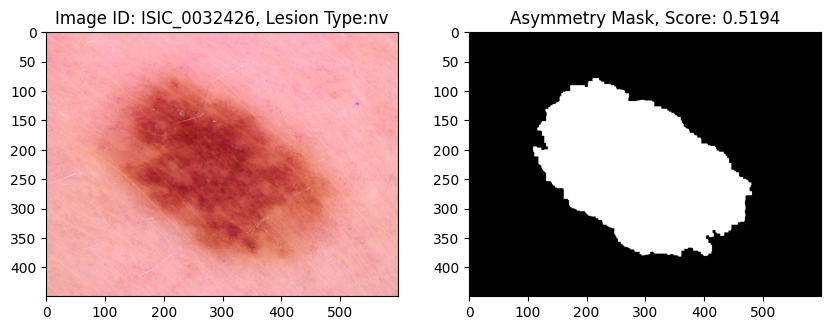

In [11]:
# Get random image from dataset
image_id, lesion_type, image = dataset_manager.get_sample_image(lesion_type=None)
binary_mask = ImageAsymmetry.create_binary_mask(image=image)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image)
axes[0].set_title(f"Image ID: {image_id}, Lesion Type:{lesion_type}")
axes[1].imshow(binary_mask, cmap='gray')
axes[1].set_title(f"Asymmetry Mask, Score: {ImageAsymmetry.calculate_asymmetry(image):.4f}")
plt.show()